# PCA

In [1]:
import numpy as np
import pandas as pd
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt

In [2]:
df = pd.read_csv("diabetes.csv")
df.head()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


In [3]:
#$slect only numeric col
num_col = ["Pregnancies","Glucose","BloodPressure","SkinThickness","Insulin","BMI","DiabetesPedigreeFunction","Age"]

In [4]:
# Handle missing values
imputer = SimpleImputer()
data_imputed = imputer.fit_transform(df[num_col])
data_clean = pd.DataFrame(data_imputed,columns=num_col)
data_clean.head()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age
0,6.0,148.0,72.0,35.0,0.0,33.6,0.627,50.0
1,1.0,85.0,66.0,29.0,0.0,26.6,0.351,31.0
2,8.0,183.0,64.0,0.0,0.0,23.3,0.672,32.0
3,1.0,89.0,66.0,23.0,94.0,28.1,0.167,21.0
4,0.0,137.0,40.0,35.0,168.0,43.1,2.288,33.0


In [5]:
# Standardize [imp for pca]
scaler = StandardScaler()
data_scaled = scaler.fit_transform(data_clean)

In [6]:
#Apply pca
pca = PCA(n_components=5)
data_pca = pca.fit_transform(data_scaled)

In [8]:
data_pca

array([[ 1.06850273,  1.23489499, -0.09592984,  0.4969902 ,  0.10998491],
       [-1.12168331, -0.73385167,  0.71293816,  0.28505622,  0.38950719],
       [-0.39647671,  1.59587594, -1.76067844, -0.07039464, -0.90647385],
       ...,
       [-0.28347525,  0.09706503,  0.07719194, -0.68756106,  0.52300926],
       [-1.06032431,  0.83706234, -0.42503045, -0.20449292, -0.95759303],
       [-0.83989172, -1.15175485,  1.00917817,  0.0869288 ,  0.08265082]])

In [9]:
#check how much info each component keeps
explained_variance = pca.explained_variance_ratio_
cumulative_variance = np.cumsum(explained_variance)

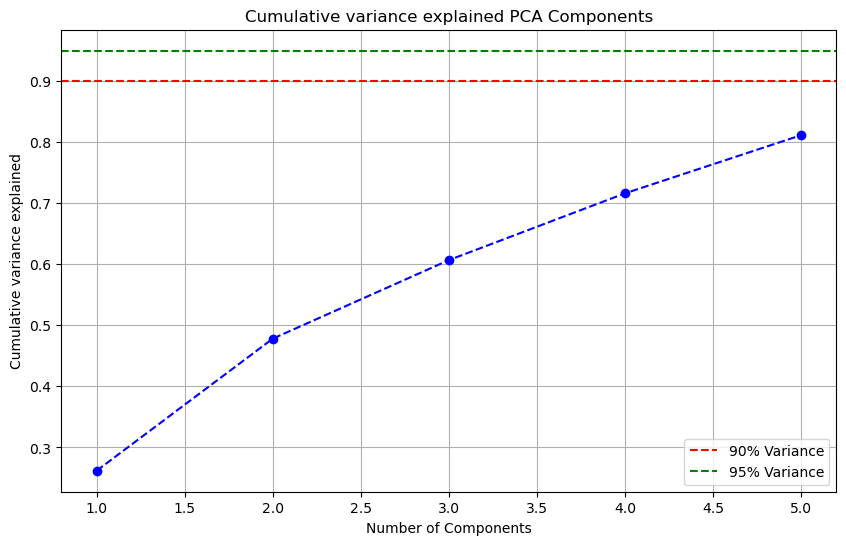

In [14]:
# Plot cum var
plt.figure(figsize=(10,6))
plt.plot(range(1,len(cumulative_variance)+1),cumulative_variance,marker='o',linestyle='--',color='b')
plt.title("Cumulative variance explained PCA Components")
plt.xlabel("Number of Components")
plt.ylabel("Cumulative variance explained")
plt.axhline(y=0.90,color='r',linestyle='--',label='90% Variance')
plt.axhline(y=0.95,color='g',linestyle='--',label='95% Variance')
plt.legend()
plt.grid(True)
plt.show()

In [ ]:
#print var info
explained_variance.round(3)

array([0.262, 0.216, 0.129, 0.109, 0.095])

In [16]:
cumulative_variance.round(3)

array([0.262, 0.478, 0.607, 0.716, 0.812])

In [18]:
# Find feature contribution [loading]
loadings = pd.DataFrame(pca.components_.T, columns=[f"PC{i+1}" for i in range (pca.n_components_)], index=num_col ) #pca.components_.T : transpose to get feature as rows
print(loadings,round(3))

                               PC1       PC2       PC3       PC4       PC5
Pregnancies               0.128432  0.593786  0.013087  0.080691  0.475606
Glucose                   0.393083  0.174029 -0.467923 -0.404329 -0.466328
BloodPressure             0.360003  0.183892  0.535494  0.055986 -0.327953
SkinThickness             0.439824 -0.331965  0.237674  0.037976  0.487862
Insulin                   0.435026 -0.250781 -0.336709 -0.349944  0.346935
BMI                       0.451941 -0.100960  0.361865  0.053646 -0.253204
DiabetesPedigreeFunction  0.270611 -0.122069 -0.433189  0.833680 -0.119810
Age                       0.198027  0.620589 -0.075248  0.071201  0.109290 3


In [19]:
#Use pc for logistic regression
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
from sklearn.linear_model import LogisticRegression


In [21]:
index_of_95 = np.argmax(cumulative_variance >= 0.95)
# np.argmax return the index of the first True. if no True found it returns 0, we must check if 95% target was actually reached at that imdex


In [22]:
if cumulative_variance[index_of_95] >= 0.95:
    n_opt = index_of_95 + 1
else:
    n_opt = len(explained_variance)
n_opt

5

In [35]:
#use the optimally round data for modelling
X_pca_reduced = data_pca[:,:n_opt]
y = df["Outcome"]

X_train, X_test, y_train, y_test = train_test_split(X_pca_reduced,y,test_size=0.3,random_state=42,stratify=y)
log_reg = LogisticRegression(max_iter=100)
log_reg.fit(X_train,y_train)

LogisticRegression()

In [36]:
y_pred = log_reg.predict(X_test)
accuracy = accuracy_score(y_test,y_pred)
print(f"Model Accuracy {accuracy:.4f}")

Model Accuracy 0.7403
